# 434 Lab 2 Report
**Name:** Austin Birkhofer

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (9, 5)

## Problem 1
I choose $X=2$ daily background mean counts and a hypothetical observed rate $Y=6$ counts/day. The daily counts are independent.

### Part A
$$S_N=\sum_i K_i,\qquad E[S_N]=NX,\quad\operatorname{Var}(S_N)=NX.$$

Convolution gives the sum distribution. Infinite Poisson support is truncated with omitted daily tail at most $10^{-12}$; probabilities are renormalized. Errors from this approximation are negligible for these plots.

Omitted daily tail = 6.48e-13


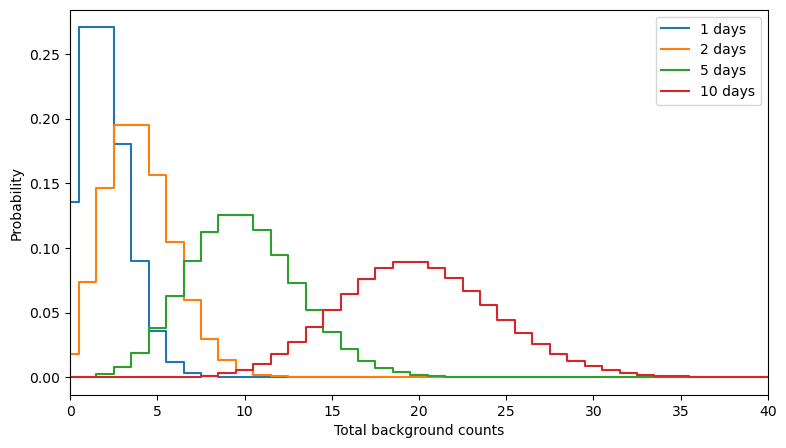

In [2]:
X = 2.0
Y = 6.0
cutoff = int(stats.poisson.ppf(1 - 1e-12, X))
x_day = np.arange(cutoff + 1) # count possibilities
p_day = stats.poisson.pmf(x_day, X) # prob of each count according to poisson
print(f"Omitted daily tail = {stats.poisson.sf(cutoff, X):.3g}")
p_day = p_day / p_day.sum()
assert np.isclose(p_day.sum(), 1)

sum_distributions = {1: p_day.copy()} # dicitionary w/ key being number of days and value is that total prob array
p_sum = p_day.copy()
for days in range(2, 101):
    p_sum = np.convolve(p_sum, p_day, mode="full")
    sum_distributions[days] = p_sum.copy()
    assert np.isclose(p_sum.sum(), 1)

for days in [1, 2, 5, 10]:
    p_sum = sum_distributions[days]
    x_sum = np.arange(len(p_sum))
    plt.step(x_sum, p_sum, where="mid", label=f"{days} days")
plt.xlim(0, 40)
plt.xlabel("Total background counts")
plt.ylabel("Probability")
plt.legend()
plt.show()

The center moves to $NX$ and the width grows as $\sqrt{NX}$. The relative width shrinks as $1/\sqrt{NX}$.

### Part B

The prob function of one day is $G(t)=e^{X(t-1)}$. Independence gets us $G(t)^N=e^{NX(t-1)}$ which is the generating function of Poisson with mean $NX$. Thus, $S_5$ ~ Poisson(10) exactly! Concpetually, if we count independent events we add our expected counts w/o changing Poisson process.

Maximum probability difference: 4.514321757392598e-13
Convolved mean: 9.999999999944585
Convolved variance: 9.99999999905798


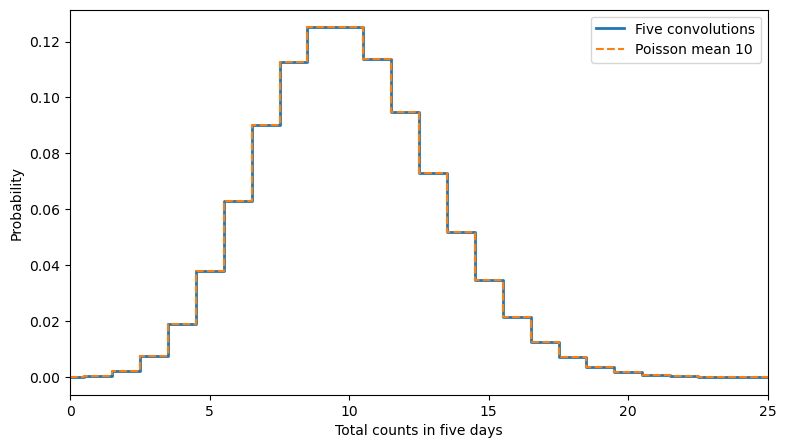

In [3]:
days = 5
p_five = sum_distributions[days]
x_five = np.arange(len(p_five))
p_exact = stats.poisson.pmf(x_five, days*X)
print("Maximum probability difference:", np.max(np.abs(p_five-p_exact)))
print("Convolved mean:", np.sum(x_five*p_five))
print("Convolved variance:", np.sum((x_five-days*X)**2*p_five))
assert np.allclose(p_five, p_exact, atol=1e-10)
plt.step(x_five, p_five, where="mid", linewidth=2, label="Five convolutions")
plt.step(x_five, p_exact, where="mid", linestyle="--", label="Poisson mean 10")
plt.xlim(0, 25)
plt.xlabel("Total counts in five days")
plt.ylabel("Probability")
plt.legend()
plt.show()

### Part C

Divide the sum positions by $N$, keeping probability masses unchanged:

$$\overline K_N=S_N/N,\quad E[\overline K_N]=X,\quad
\sigma_{\overline K_N}=\sqrt{X/N}.$$

The average is a scaled Poisson, not a usual Poisson count so its support is $0,1/N,2/N,\ldots$. The sum remains exactly Poisson while its standardized shape becomes approximately Gaussian as $NX$ grows. Agrees with the central limit theorem I believe!

  1 days: mean=2.0000, std=1.4142
  5 days: mean=2.0000, std=0.6325
 20 days: mean=2.0000, std=0.3162
100 days: mean=2.0000, std=0.1414


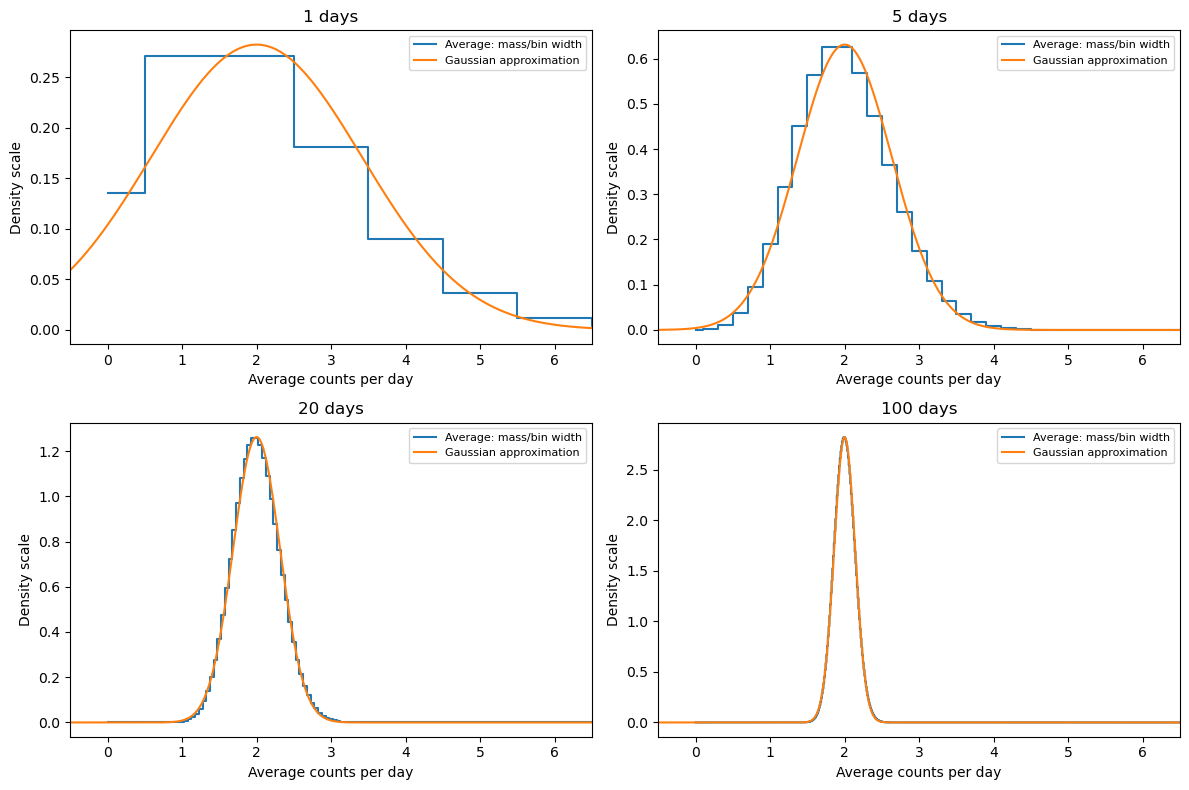

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, days in zip(axes.flat, [1, 5, 20, 100]):
    p_sum = sum_distributions[days]
    x_average = np.arange(len(p_sum)) / days
    width = 1/days
    mean = np.sum(x_average*p_sum)
    variance = np.sum((x_average-mean)**2*p_sum)
    assert np.isclose(mean, X, atol=1e-8)
    assert np.isclose(variance, X/days, atol=1e-8)
    ax.step(x_average, p_sum/width, where="mid",
            label="Average: mass/bin width")
    x = np.linspace(-0.5, 6.5, 1000)
    ax.plot(x, stats.norm.pdf(x, loc=X, scale=np.sqrt(X/days)),
            label="Gaussian approximation")
    ax.set(xlim=(-0.5, 6.5), xlabel="Average counts per day",
           ylabel="Density scale", title=f"{days} days")
    ax.legend(fontsize=8)
    print(f"{days:3d} days: mean={mean:.4f}, std={np.sqrt(variance):.4f}")
fig.tight_layout()
plt.show()

### Part D

Choose $N=5$ days and observed total $k_{\mathrm{obs}}=YN=30$. Under background only,

$$p=P(S_5\geq30\mid\lambda=10)=\sum_{k=30}^{\infty}e^{-10}\frac{10^k}{k!},\quad z=\Phi^{-1}(1-p).$$

Use `sf(k_obs - 1)` to include the observed count and `norm.isf(p)` for a numerically stable upper-tail inverse. This is the probability of an equally or more extreme count under background only.

In [5]:
N = 5
observed = int(Y*N)
p = stats.poisson.sf(observed - 1, N*X)
z = stats.norm.isf(p)
print(f"Observed count = {observed}; expected background = {N*X:g}")
print(f"Upper-tail probability = {p:.8g}")
print(f"Equivalent significance = {z:.4f} sigma")

Observed count = 30; expected background = 10
Upper-tail probability = 2.5099512e-07
Equivalent significance = 5.0256 sigma


## Problem 2

I chose the Rayleigh distrubition with scale parameter $s=2$.

$$f(x)=\frac{x}{s^2}e^{-x^2/(2s^2)},\quad x\geq0,$$

$$\mu=s\sqrt{\pi/2},\qquad \sigma^2=\frac{4-\pi}{2}s^2.$$

### Part A

Create bin probabilities by integrating the CDF over fine bins. After $N$ convolutions I divided the positions by $N$ and divide the masses by the new bin width to plot density.

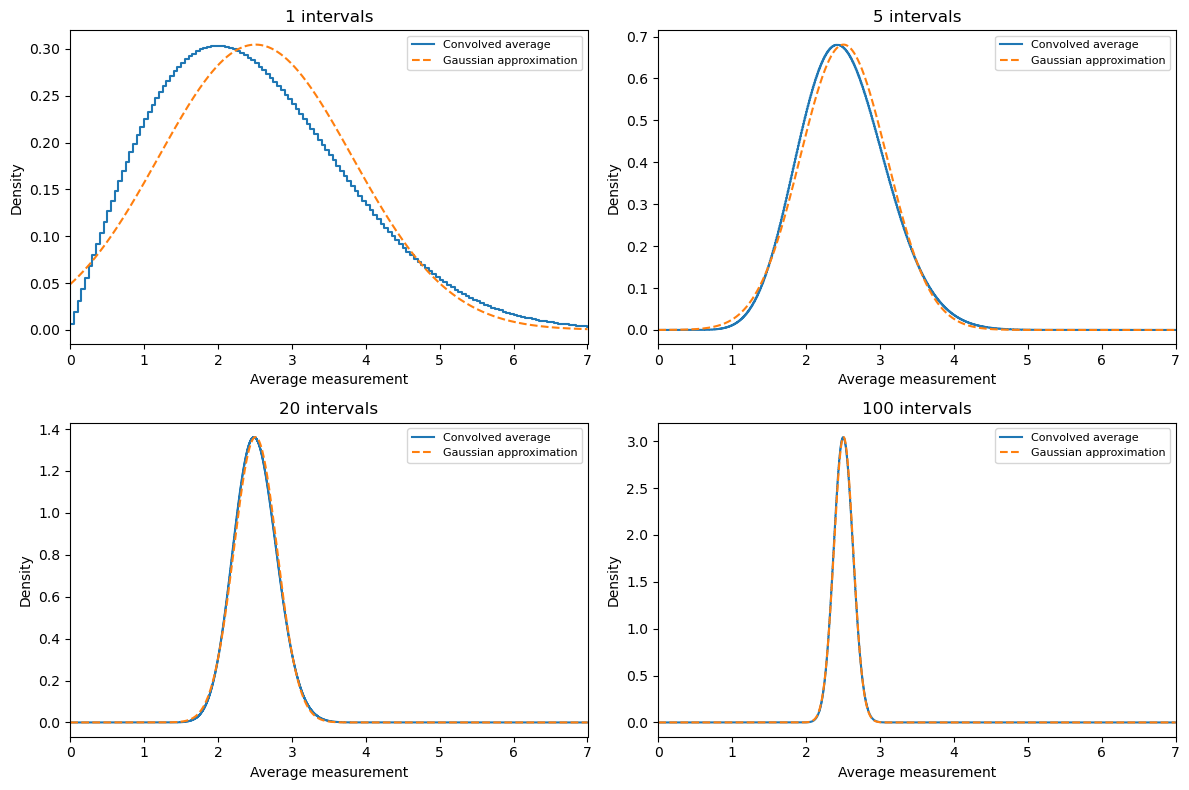

In [6]:
scale = 2.0
dx = 0.05
maximum = stats.rayleigh.ppf(1 - 1e-12, scale=scale)
edges = np.arange(0, maximum + dx, dx)
x_day = (edges[:-1] + edges[1:]) / 2
p_day = np.diff(stats.rayleigh.cdf(edges, scale=scale))
p_day = p_day / p_day.sum()
mu = stats.rayleigh.mean(scale=scale)
variance = stats.rayleigh.var(scale=scale)
assert np.isclose(p_day.sum(), 1)
assert np.isclose(np.sum(x_day*p_day), mu, atol=dx**2)
assert np.isclose(np.sum((x_day-mu)**2*p_day), variance, atol=dx**2)

rayleigh_sums = {1: p_day.copy()}
p_sum = p_day.copy()
for intervals in range(2, 101):
    p_sum = np.convolve(p_sum, p_day, mode="full")
    rayleigh_sums[intervals] = p_sum.copy()
assert np.isclose(p_sum.sum(), 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, intervals in zip(axes.flat, [1, 5, 20, 100]):
    p_sum = rayleigh_sums[intervals]
    x_sum = intervals*x_day[0] + dx*np.arange(len(p_sum))
    x_average = x_sum / intervals
    ax.step(x_average, p_sum/(dx/intervals), where="mid",
            label="Convolved average")
    x = np.linspace(0, 7, 1000)
    ax.plot(x, stats.norm.pdf(x, loc=mu, scale=np.sqrt(variance/intervals)),
            "--", label="Gaussian approximation")
    ax.set(xlim=(0, 7), xlabel="Average measurement", ylabel="Density",
           title=f"{intervals} intervals")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Part B

The mean stays near 2.5066, the standard deviation decreases as $1/\sqrt N$, and the positive skewness decreases as $\gamma_1/\sqrt N$. The average approaches Gaussian in standardized coordinates by the central limit theorem.

In [14]:
print("N        skewness  max CDF difference")
passing = []
for intervals in [1, 2, 5, 10, 20, 50, 100]:
    p_sum = rayleigh_sums[intervals]
    x_average = (intervals*x_day[0] + dx*np.arange(len(p_sum))) / intervals
    # Compare cumulative bin probabilities at the right bin boundaries.
    right_edges = x_average + dx/(2*intervals)
    normal_cdf = stats.norm.cdf(right_edges, loc=mu,
                                scale=np.sqrt(variance/intervals))
    difference = np.max(np.abs(np.cumsum(p_sum)-normal_cdf))
    skewness = stats.rayleigh.stats(scale=scale, moments="s") / np.sqrt(intervals)
    print(f"{intervals:3d}   {skewness:10.5f}   {difference:.6f}")
    if difference < 0.01:
        passing.append(intervals)
print("first tested N satisfying a 0.01 CDF criterion:", passing[0])

N        skewness  max CDF difference
  1      0.63111   0.046544
  2      0.44626   0.030944
  5      0.28224   0.019061
 10      0.19957   0.013371
 20      0.14112   0.009418
 50      0.08925   0.005943
100      0.06311   0.004199
first tested N satisfying a 0.01 CDF criterion: 20


## Problem 3

I chose a Gaussian noise width $X=2$ brightness units and candidate brightness $Y=10.4$, with background mean zero. Let $F(y)=\Phi(y/X)$.

### Part A

The question is: under background only what is the probability that this specified pixel has brightness at least $Y$?

$$p_{\mathrm{local}}=1-F(Y),\qquad z_{\mathrm{local}}=Y/X=5.2.$$

In [17]:
X_noise = 2.0
Y_signal = 10.4
p_local = stats.norm.sf(Y_signal, loc=0, scale=X_noise)
z_local = stats.norm.isf(p_local)
print(f"Local p = {p_local:.8g}")
print(f"Local significance = {z_local:.4f} sigma")

Local p = 9.9644263e-08
Local significance = 5.2000 sigma


### Part B

Question: what is the probability that at least one of the $m=10^4$ background pixels is as bright as the candidate?

For independent pixels and max $W$,

$$P(W\leq y)=F(y)^m,$$

$$f_W(y)=m f(y)F(y)^{m-1},\qquad
P(W\geq Y)=1-[1-p_{\mathrm{local}}]^m.$$

For small $mp_{\mathrm{local}}$, the global tail is approx $mp_{\mathrm{local}}$.

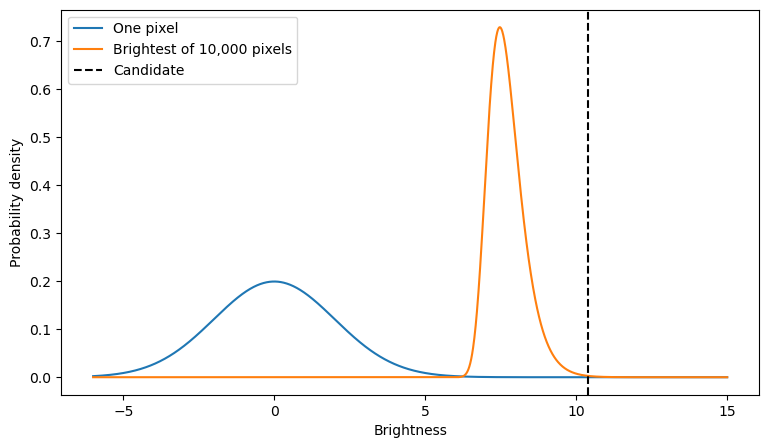

In [16]:
m = 10000
x = np.linspace(-6, 15, 2000)
log_cdf = stats.norm.logcdf(x, loc=0, scale=X_noise)
maximum_pdf = np.exp(np.log(m) + stats.norm.logpdf(x, loc=0, scale=X_noise)
                     + (m-1)*log_cdf)
plt.plot(x, stats.norm.pdf(x, loc=0, scale=X_noise), label="One pixel")
plt.plot(x, maximum_pdf, label="Brightest of 10,000 pixels")
plt.axvline(Y_signal, color="black", linestyle="--", label="Candidate")
plt.xlabel("Brightness")
plt.ylabel("Probability density")
plt.legend()
plt.show()

### Part C

Use the maximum's upper-tail probability, then convert it into Gaussian equivalent sigma.

In [21]:
#calculation of 1 - (1 - p_local)**m.
p_global = -np.expm1(m * np.log1p(-p_local))
z_global = stats.norm.isf(p_global)
print(f"Global p = {p_global:.8g}")
print(f"Global significance = {z_global:.4f} sigma")
print("meets 5-sigma criterion:", z_global >= 5)

Global p = 0.0009959464
Global significance = 3.0914 sigma
meets 5-sigma criterion: False


## Problem 4 — Five-sigma discovery thresholds

Let $\alpha=1-\Phi(5)$ be the one sided five sigma tail prob.

### Part A

$$Y_1=X\Phi^{-1}(1-\alpha)=5X=10.$$

### Part B

I require $1-F(Y_m)^m=\alpha$. Thus

$$F(Y_m)=(1-\alpha)^{1/m},$$

$$Y_m=X\Phi^{-1}\bigl((1-\alpha)^{1/m}\bigr).$$

In [23]:
alpha = stats.norm.sf(5)
Y_one = X_noise * stats.norm.isf(alpha)
p_single_required = -np.expm1(np.log1p(-alpha) / m)
Y_many = X_noise * stats.norm.isf(p_single_required)
print(f"one sided 5 sigma tail = {alpha:.8g}")
print(f"one pixel threshold = {Y_one:.4f}")
print(f"10,000 pixel threshold = {Y_many:.4f}")
print(f"brightness ratio = {Y_many/Y_one:.4f}")
print(f"increase = {100*(Y_many/Y_one-1):.2f}%")
check = -np.expm1(m*np.log1p(-stats.norm.sf(Y_many, scale=X_noise)))
assert np.isclose(check, alpha, rtol=1e-8)

one sided 5 sigma tail = 2.8665157e-07
one pixel threshold = 10.0000
10,000 pixel threshold = 13.1011
brightness ratio = 1.3101
increase = 31.01%


### Part C

The trials factor multiplies a small tail probability but the Gaussian tail falls quick roughly as $e^{-z^2/2}/z$. An increase in brightness then produces a large decrease in tail prob. The search threshold is 6.55 times the noise widt instead of 50,000 times it so about a 31% brightness increase over a five-sigma threshold.

### Part D

For small tails, $p_{\mathrm{single}}\approx\alpha/m$. If I ignore log factors in the Gaussian tail then it gives the scaling $z_m^2\approx z_1^2+2\ln m$. So gives small decent changes.

Trials       threshold/noise     brightness     ratio to one pixel
        1         5.00000        10.00000    1.00000
       10         5.42693        10.85387    1.08539
      100         5.82436        11.64873    1.16487
     1000         6.19760        12.39520    1.23952
    10000         6.55054        13.10108    1.31011
  1000000         7.20669        14.41337    1.44134
100000000         7.80969        15.61937    1.56194


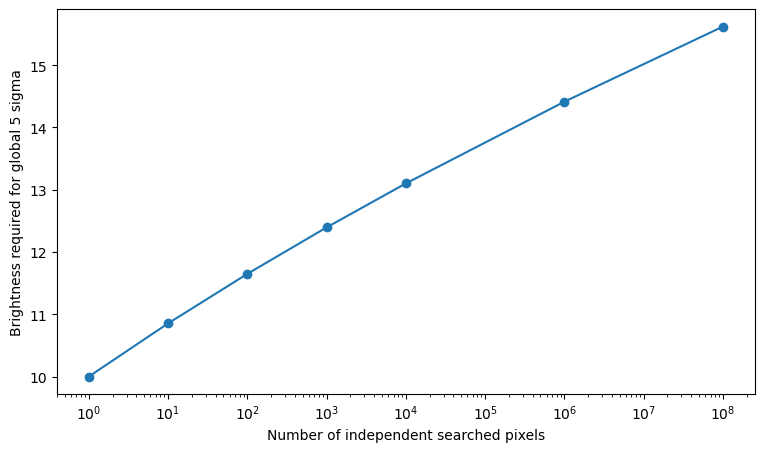

In [24]:
trial_counts = np.array([1, 10, 100, 1000, 10000, 1000000, 100000000])
thresholds = []
print("Trials       threshold/noise     brightness     ratio to one pixel")
for trials in trial_counts:
    single_tail = -np.expm1(np.log1p(-alpha) / trials)
    z_required = stats.norm.isf(single_tail)
    thresholds.append(z_required * X_noise)
    print(f"{trials:9d}    {z_required:12.5f}    {z_required*X_noise:12.5f}    {z_required/5:.5f}")
plt.semilogx(trial_counts, thresholds, "o-")
plt.xlabel("Number of independent searched pixels")
plt.ylabel("Brightness required for global 5 sigma")
plt.show()

### Extra Credit

For any continuous CDF $F$, the threshold stays at $Y_m=F^{-1}((1-\alpha)^{1/m})$. Tail shape determines how far the threshold must go.

For exponential scale $\tau$, $P(X>y)=e^{-y/\tau}$, so

$$Y_m\approx\tau\ln(m/\alpha)=Y_1+\tau\ln m.$$

For a Pareto tail $P(X>y)=(y_{\min}/y)^a$,

$$Y_m\approx y_{\min}(m/\alpha)^{1/a},\qquad
Y_m/Y_1\approx m^{1/a}.$$

Thus heavy power law tails get a much larger sensitivity penalty than Gaussian tails.